# 12 · Transfer learning of the published STAMP model

STAMP (Ben Cohen et al. 2025) published a breast model for TP53: a graph network (GCN) with 344 genes, trained with 625 TCGA tumors. A published model like this one is, in principle, ready to use in another hospital. This notebook takes it **as it is, with its published weights**, and puts it through our design in CPTAC and SMC. Then it compares it with our MLP.

| Strategy | What it does | Compared with |
|---|---|---|
| **S1. STAMP: apply directly** | Its published weights, without local patients | MLP strategy 1: AUC on each exam |
| **S2. STAMP + fine-tuning** | Its weights, adjusted with n local patients (every layer) | MLP strategy 2: SD of the AUC across the 100 repetitions, and mean AUC |

The question is whether our approach gives a **smaller SD** than STAMP. Apply directly has SD 0 by construction (one AUC per exam), so the SD is only compared with fine-tuning.

**Rules fixed before running (decisions of 29-Oct-2026):**
1. The 344 genes of the model, **TP53 and INGX included**, because the weights were trained with them. Genes a cohort does not have enter as 0 after the z-score (SOD2 in CPTAC), as STAMP did in METABRIC.
2. Each cohort is normalized with the patients outside the exam, without labels (rule of 12-Oct). STAMP also used a z-score to apply its model to METABRIC.
3. Fine-tuning starts from the STAMP training values: Adam with weight decay 1e-4. The learning rate and epochs are chosen with **the same rehearsal and the same rule as our MLP** (notebook 07, TCGA → METABRIC). The STAMP model never saw METABRIC, so the rehearsal works the same way. The tie-break rule matters: a very small learning rate barely changes the network and gives an SD close to 0 (14-Oct). That is why both networks use the same rule, and the sensitivity setting (learning rate 10 times larger) is also reported.
4. Batch = all n patients, class weights, no early stopping in the local stage, same exams and repetitions as notebook 04.

The GCN has no dropout and is trained with all n patients in one batch. So its fine-tuning gives the same result for the same patients. Its SD only comes from which patients were drawn, which is exactly what the study measures.

**Input:** the STAMP model file, `X_stamp_*.parquet` (notebook 10), the exams and repetitions (04), `auc_red.csv` (08) and `auc_red_343.csv` (11).
**Output:** `results/tables/12_ajuste_elegido.json`, `12_comparacion.csv`, `12_aplicar_directo.csv` and `data/experiment/auc_stamp.csv`.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torch import nn

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import cargar, cargar_stamp, pesos_clase, pitman_morgan, zscore

EXP = ROOT / "data" / "experiment"
TAB = ROOT / "results" / "tables"
PARTS_REHEARSAL, PARTS = EXP / "partes_12_ensayo", EXP / "partes_12"
PARTS_REHEARSAL.mkdir(exist_ok=True)
PARTS.mkdir(exist_ok=True)

N_LOCAL, N_EXAM, N_EXAMS, N_REPS = [10, 15, 20, 40], 40, 5, 20   # rehearsal, as notebook 07
RATES, EPOCHS = [1e-5, 1e-4, 1e-3], [10, 30, 100]                # fine-tuning grid of notebook 07
TARGETS = ["CPTAC", "SMC 2018"]

## Step 1 · The STAMP network with its published weights

Same network as in the replication (`replicacion_STAMP.ipynb`): embedding of 50, one graph layer with 40 channels (20 from the neighbors and 20 from the gene itself), one gene per group (344 → 172) and a final layer with 2 outputs. The graph, the gene groups and the weights come from the `.pt` file.

In [2]:
stamp = cargar_stamp()
genes = list(stamp.X.columns)
ADJ = torch.tensor(stamp.adjs[0].toarray(), dtype=torch.float32)
GROUPS = torch.tensor(stamp.centroids[0])


class GCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Parameter(torch.empty(344, 50))
        self.vecinos = nn.Conv1d(50, 20, kernel_size=1)
        self.propio = nn.Conv1d(50, 20, kernel_size=1)
        self.salida = nn.Linear(172 * 40, 2)

    def forward(self, x):                                       # x: patients × genes
        h = (x.unsqueeze(2) * self.emb).transpose(1, 2)         # patients × 50 × genes
        h = torch.cat([self.vecinos(h @ ADJ.T), self.propio(h)], dim=1).relu()
        h = h[:, :, GROUPS].transpose(1, 2)                     # one gene per group: patients × 172 × 40
        return self.salida(h.flatten(1))


layer, final = stamp._modules["conv_layers"][0], stamp._modules["my_logistic_layers"][0]
PUBLISHED = {"emb": stamp._modules["emb"]._parameters["emb"],
             "vecinos.weight": layer._modules["linear"].weight, "vecinos.bias": layer._modules["linear"].bias,
             "propio.weight": layer._modules["eye_linear"].weight, "propio.bias": layer._modules["eye_linear"].bias,
             "salida.weight": final.weight, "salida.bias": final.bias}


def published():
    net = GCN()
    net.load_state_dict({k: v.detach().clone() for k, v in PUBLISHED.items()})
    return net


def prob(net, x):
    net.eval()
    with torch.no_grad():
        return net(torch.as_tensor(x, dtype=torch.float32)).softmax(dim=1)[:, 1].numpy()


def fine_tune(rate, epochs, rep, x_loc, y_loc, x_exam, y_exam):
    """Fine-tuning of the published weights, every layer free. Returns {epoch: (AUC exam, AUC local)}."""
    torch.manual_seed(rep)
    net = published()
    opt = torch.optim.Adam(net.parameters(), lr=rate, weight_decay=1e-4)   # optimizer and weight decay of STAMP
    w = pesos_clase(y_loc)
    xl, yl = torch.as_tensor(x_loc, dtype=torch.float32), torch.as_tensor(y_loc)
    out = {}
    for ep in range(1, max(epochs) + 1):
        net.train()
        loss = nn.functional.cross_entropy(net(xl), yl, weight=torch.tensor([w[0], w[1]], dtype=torch.float32))
        opt.zero_grad()
        loss.backward()
        opt.step()
        if ep in epochs:
            out[ep] = (roc_auc_score(y_exam, prob(net, x_exam)), roc_auc_score(y_loc, prob(net, x_loc)))
    return out

Check: with all METABRIC normalized together (as STAMP did), the published weights should give an AUC close to the 0.900 of the replication (paper: 0.902). Small differences can come from the rule for genes with more than one row (here the one of notebook 02).

In [3]:
x_meta, y_meta = cargar("METABRIC", stamp=True)
print(f"METABRIC with the published weights: AUC {roc_auc_score(y_meta, prob(published(), zscore(x_meta, x_meta.index).to_numpy())):.3f}")

METABRIC with the published weights: AUC 0.900


## Step 2 · Rehearsal TCGA → METABRIC (as notebook 07)

Same exams of METABRIC, same draws of local patients, same seeds, same grid and same choice rule as the rehearsal of our MLP. The sensitivity setting is the chosen learning rate × 10.

In [4]:
y_m = y_meta.to_numpy()
for e in range(N_EXAMS):
    part = PARTS_REHEARSAL / f"examen{e + 1}.parquet"
    if part.exists():
        continue
    rest, exam = train_test_split(np.arange(len(y_m)), test_size=N_EXAM, stratify=y_m, random_state=2026 + e)
    z = zscore(x_meta, x_meta.index[rest]).to_numpy()
    rows = [{"examen": e + 1, "estrategia": 1, "n": 0, "auc": roc_auc_score(y_m[exam], prob(published(), z[exam]))}]
    for n in N_LOCAL:
        for r in range(N_REPS):
            loc, _ = train_test_split(rest, train_size=n, stratify=y_m[rest], random_state=100000 * e + 1000 * n + r)
            for rate in RATES:
                out = fine_tune(rate, EPOCHS, r, z[loc], y_m[loc], z[exam], y_m[exam])
                rows += [{"examen": e + 1, "estrategia": 2, "tasa": rate, "epocas": ep, "n": n, "repeticion": r,
                          "auc": a, "auc_locales": a_loc} for ep, (a, a_loc) in out.items()]
    pd.DataFrame(rows).to_parquet(part)
    print(f"Exam {e + 1} done")

rehearsal = pd.concat([pd.read_parquet(p) for p in sorted(PARTS_REHEARSAL.glob("examen*.parquet"))], ignore_index=True)
ft = rehearsal[rehearsal.estrategia == 2]
grid = (ft.groupby(["tasa", "epocas", "n", "examen"]).auc.agg(["mean", "std"])
        .groupby(["tasa", "epocas"]).mean().rename(columns={"mean": "AUC promedio", "std": "DE entre repeticiones"}))
near = grid[grid["AUC promedio"] >= grid["AUC promedio"].max() - 0.005]
rate, epochs = near["DE entre repeticiones"].idxmin()
setups = {"principal": {"tasa": float(rate), "epocas": int(epochs)},
          "sensibilidad": {"tasa": float(rate) * 10, "epocas": int(epochs)}}
(TAB / "12_ajuste_elegido.json").write_text(json.dumps(setups, indent=2))
print("Apply directly in METABRIC (mean of 5 exams):", round(rehearsal[rehearsal.estrategia == 1].auc.mean(), 3))
display(grid.round(4))
setups

Exam 1 done


Exam 2 done


Exam 3 done


Exam 4 done


Exam 5 done


Apply directly in METABRIC (mean of 5 exams): 0.849


AUC promedio  DE entre repeticiones
tasa    epocas                                     
0.00001 10.0          0.8490                 0.0009
        30.0          0.8492                 0.0022
        100.0         0.8499                 0.0046
0.00010 10.0          0.8497                 0.0046
        30.0          0.8495                 0.0088
        100.0         0.8427                 0.0226
0.00100 10.0          0.8428                 0.0224
        30.0          0.8258                 0.0405
        100.0         0.8173                 0.0485

{'principal': {'tasa': 1e-05, 'epocas': 10},
 'sensibilidad': {'tasa': 0.0001, 'epocas': 10}}

## Step 3 · CPTAC and SMC

The STAMP model sees CPTAC and SMC here for the first time. Nothing is chosen in this step.

In [5]:
exams = pd.read_csv(EXP / "examenes.csv")
reps = pd.read_csv(EXP / "repeticiones.csv")

for name in TARGETS:
    x, y = cargar(name, stamp=True)
    for e in range(1, 6):
        part = PARTS / f"{name.replace(' ', '_')}_examen{e}.parquet"
        if part.exists():
            continue
        start = time.time()
        exam_ids = exams.query("cohorte == @name and examen == @e").muestra
        z = zscore(x, x.index.difference(exam_ids))
        x_exam, y_exam = z.loc[exam_ids].to_numpy(), y.loc[exam_ids].to_numpy()
        rows = [{"estrategia": 1, "variante": "principal", "n": 0, "repeticion": 0, "auc": roc_auc_score(y_exam, prob(published(), x_exam))}]
        groups = reps.query("cohorte == @name and examen == @e").groupby(["n", "repeticion"]).muestra.apply(list)
        for (n, r), ids in groups.items():
            x_loc, y_loc = z.loc[ids].to_numpy(), y.loc[ids].to_numpy()
            for v, s in setups.items():
                a, a_loc = fine_tune(s["tasa"], [s["epocas"]], r, x_loc, y_loc, x_exam, y_exam)[s["epocas"]]
                rows.append({"estrategia": 2, "variante": v, "n": n, "repeticion": r, "auc": a, "auc_locales": a_loc})
        pd.DataFrame(rows).assign(cohorte=name, examen=e).to_parquet(part)
        print(f"{name} exam {e}: {len(rows):,} networks in {(time.time() - start) / 60:.0f} min")

keys = ["cohorte", "examen", "estrategia", "variante", "n", "repeticion"]
auc = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("*_examen*.parquet"))], ignore_index=True)
assert auc.groupby(["cohorte", "estrategia", "variante", "n"]).size().isin([5, 500]).all(), "missing networks"
auc[keys + ["auc", "auc_locales"]].to_csv(EXP / "auc_stamp.csv", index=False)

CPTAC exam 1: 801 networks in 10 min


CPTAC exam 2: 801 networks in 9 min


CPTAC exam 3: 801 networks in 9 min


CPTAC exam 4: 801 networks in 9 min


CPTAC exam 5: 801 networks in 9 min


SMC 2018 exam 1: 1,001 networks in 10 min


SMC 2018 exam 2: 1,001 networks in 10 min


SMC 2018 exam 3: 1,001 networks in 10 min


SMC 2018 exam 4: 1,001 networks in 10 min


SMC 2018 exam 5: 1,001 networks in 5 min


## Step 4 · Comparison with our MLP

All the models used the same exams and the same local patients in each repetition. So, in each exam, the 100 AUCs of STAMP and the 100 AUCs of the MLP are paired by repetition, and their SDs are compared with Pitman-Morgan. Each exam is reported separately (decision of 20-Oct).

- **z > 0:** our MLP has the smaller SD.
- **Reduction:** 1 − SD of the MLP / SD of STAMP.

The main comparison is at n = 10 with the main setting of each network. The MLP of 343 genes is the extra analysis.

In [6]:
models = {"MLP 18,040 genes": EXP / "auc_red.csv", "MLP 343 genes": EXP / "auc_red_343.csv", "STAMP": EXP / "auc_stamp.csv"}
everything = pd.concat([pd.read_csv(p).assign(modelo=m) for m, p in models.items()], ignore_index=True)
everything = everything[everything.estrategia.isin([1, 2])]

direct = everything[everything.estrategia == 1].pivot_table(index=["cohorte", "examen"], columns="modelo", values="auc")
direct.to_csv(TAB / "12_aplicar_directo.csv")
display(direct.round(3))

rows = []
ft = everything[everything.estrategia == 2]
for (cohort, variant, n, exam), g in ft.groupby(["cohorte", "variante", "n", "examen"]):
    w = g.pivot(index="repeticion", columns="modelo", values="auc")
    for mlp in ("MLP 18,040 genes", "MLP 343 genes"):
        p, z = pitman_morgan(w[mlp], w["STAMP"])
        rows.append({"cohorte": cohort, "variante": variant, "n": n, "examen": exam, "mlp": mlp,
                     "auc_mlp": w[mlp].mean(), "auc_stamp": w["STAMP"].mean(),
                     "de_mlp": w[mlp].std(), "de_stamp": w["STAMP"].std(),
                     "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
comparison = pd.DataFrame(rows)
comparison.to_csv(TAB / "12_comparacion.csv", index=False)

main = comparison[(comparison.n == 10) & (comparison.variante == "principal")]
(main.assign(menor_mlp=(main.p < 0.05) & (main.z > 0), menor_stamp=(main.p < 0.05) & (main.z < 0))
 .groupby(["cohorte", "mlp"])
 .agg(de_mlp=("de_mlp", "mean"), de_stamp=("de_stamp", "mean"), reduccion=("reduccion_de", "median"),
      examenes_mlp_menor=("menor_mlp", "sum"), examenes_stamp_menor=("menor_stamp", "sum")).round(4))

modelo           MLP 18,040 genes  MLP 343 genes  STAMP
cohorte  examen                                        
CPTAC    1                  0.943          0.958  0.966
         2                  0.909          0.909  0.927
         3                  0.930          0.927  0.911
         4                  0.935          0.891  0.909
         5                  0.951          0.953  0.914
SMC 2018 1                  0.872          0.912  0.895
         2                  0.875          0.872  0.757
         3                  0.907          0.900  0.794
         4                  0.877          0.857  0.832
         5                  0.797          0.772  0.777

/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/home/eduardo.tello/.conda/envs/tp53dl/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid valu

/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})
/tmp/ipykernel_1454554/1077096887.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  "reduccion_de": 1 - w[mlp].std() / w["STAMP"].std(), "z": z, "p": p})


de_mlp  de_stamp  reduccion  examenes_mlp_menor  \
cohorte  mlp                                                                 
CPTAC    MLP 18,040 genes  0.0009    0.0005    -0.9311                   1   
         MLP 343 genes     0.0011    0.0005    -1.9602                   2   
SMC 2018 MLP 18,040 genes  0.0017    0.0008    -1.6377                   0   
         MLP 343 genes     0.0019    0.0008    -2.7288                   0   

                           examenes_stamp_menor  
cohorte  mlp                                     
CPTAC    MLP 18,040 genes                     3  
         MLP 343 genes                        3  
SMC 2018 MLP 18,040 genes                     5  
         MLP 343 genes                        4

Columns: mean SD of each model across the 5 exams, median SD reduction, and in how many of the 5 exams the difference is significant (p < 0.05) in favor of each model. The full table, with every n and the sensitivity setting, is in `12_comparacion.csv`.

## Figure

Row 1: AUC of each network applied directly, per exam (dotted line = mean of the 5 exams). Rows 2 and 3: SD of the AUC across repetitions after fine-tuning (mean of the 5 exams), with the chosen setting and with the sensitivity setting. The y axes of rows 2 and 3 have different scales.

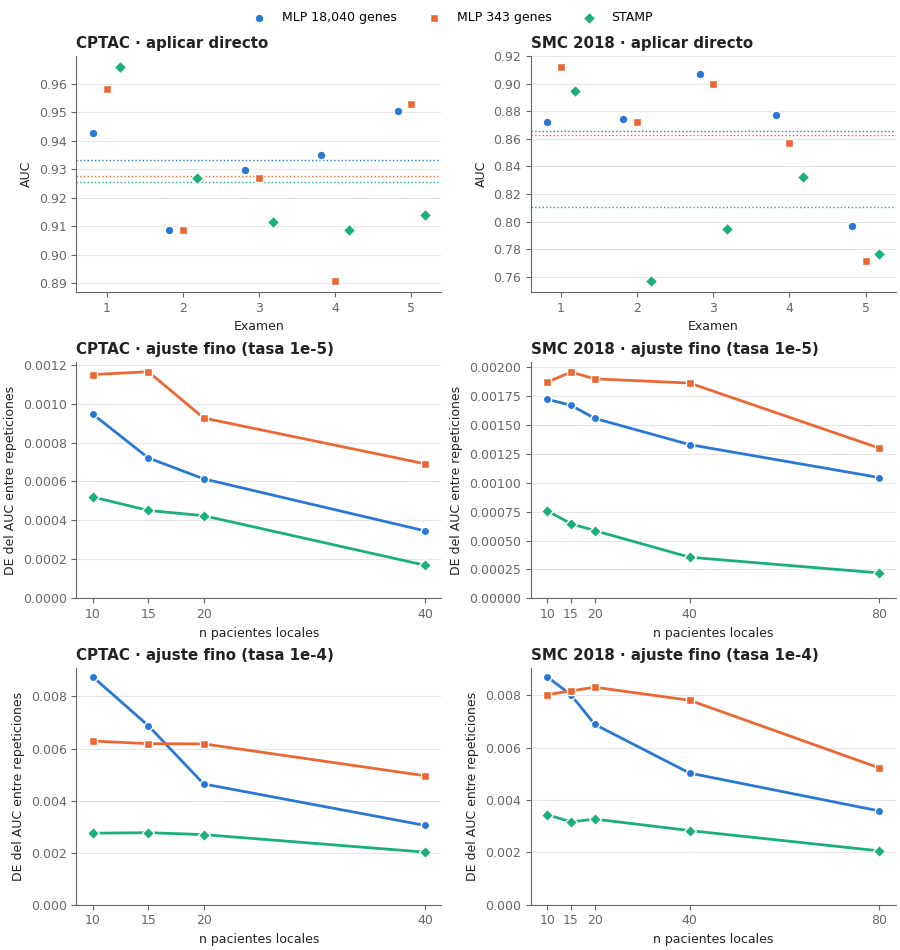

In [ ]:
import matplotlib.pyplot as plt

FIG = ROOT / "results" / "figures"
COLOR = {"MLP 18,040 genes": "#2a78d6", "MLP 343 genes": "#eb6834", "STAMP": "#1baf7a"}
MARK = {"MLP 18,040 genes": "o", "MLP 343 genes": "s", "STAMP": "D"}
INK, MUTED, GRID = "#222", "#666", "#e6e6e6"
direct_tab = pd.read_csv(TAB / "12_aplicar_directo.csv")
comp = pd.read_csv(TAB / "12_comparacion.csv")
cohorts = ["CPTAC", "SMC 2018"]

plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(3, 2, figsize=(9, 9.5), constrained_layout=True)

for ax, coh in zip(axes[0], cohorts):
    d = direct_tab[direct_tab.cohorte == coh]
    for k, (m, c) in enumerate(COLOR.items()):
        ax.scatter(d.examen + (k - 1) * 0.18, d[m], s=40, color=c, marker=MARK[m], edgecolor="white", linewidth=1, label=m, zorder=3)
        ax.axhline(d[m].mean(), color=c, lw=1, ls=":", zorder=2)
    ax.set_title(f"{coh} · aplicar directo", loc="left", color=INK, fontweight="bold")
    ax.set(xticks=range(1, 6), xlabel="Examen", ylabel="AUC")
    ax.grid(axis="y", color=GRID, lw=0.8)

for row, var, label in [(1, "principal", "tasa 1e-5"), (2, "sensibilidad", "tasa 1e-4")]:
    for ax, coh in zip(axes[row], cohorts):
        c = comp[(comp.cohorte == coh) & (comp.variante == var)]
        series = {m: c[c.mlp == m].groupby("n").de_mlp.mean() for m in ["MLP 18,040 genes", "MLP 343 genes"]}
        series["STAMP"] = c.groupby("n").de_stamp.mean()
        for m, s in series.items():
            ax.plot(s.index, s.values, color=COLOR[m], lw=2, marker=MARK[m], ms=6, markeredgecolor="white", label=m)
        ax.set_title(f"{coh} · ajuste fino ({label})", loc="left", color=INK, fontweight="bold")
        ax.set(xticks=sorted(c.n.unique()), xlabel="n pacientes locales", ylabel="DE del AUC entre repeticiones")
        ax.set_ylim(0, None)
        ax.grid(axis="y", color=GRID, lw=0.8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, frameon=False)
fig.savefig(FIG / "12_stamp_vs_mlp.png", dpi=200, facecolor="white")
plt.show()